In [ ]:
!pip install pyxlsb

import pandas as pd

import numpy as np

import matplotlib.pyplot as plt

import seaborn as sns

from sklearn.preprocessing import MinMaxScaler

from tensorflow.keras.models import Sequential

from tensorflow.keras.layers import LSTM, Dense, Dropout

from sklearn.metrics import mean_squared_error, mean_absolute_error



In [ ]:
# 1. 데이터 로드 및 '시계열 합치기' 보정 (가장 중요)
file_name = '2023 하행.xlsx'
df_raw = pd.read_excel(file_name)

# [보정] 교통량과 속도 행을 각각 분리해서 옆으로 붙입니다.
vol_raw = df_raw[df_raw.apply(lambda r: '지점총교통량' in str(r.values), axis=1)].copy()
speed_raw = df_raw[df_raw.apply(lambda r: '평균통행속도' in str(r.values), axis=1)].copy()

def get_clean(target_df, val_idx):
    if len(target_df) == 0:
        return pd.DataFrame(columns=['열1', '값'])

    res = pd.DataFrame()

    # [수정] '일자' 열을 확실하게 날짜/문자열로 처리
    # errors='coerce'를 넣어 숫자가 들어와도 에러 없이 처리합니다.
    res['일자_base'] = pd.to_datetime(target_df.iloc[:, 0], errors='coerce')

    # [수정] SyntaxWarning 해결: 앞에 r을 붙여 r'(\d+)'로 표기합니다.
    h = target_df.iloc[:, 5].astype(str).str.extract(r'(\d+)').fillna('00')
    m = target_df.iloc[:, 7].astype(str).str.extract(r'(\d+)').fillna('00')

    # 날짜가 유효하지 않은(NaT) 행은 제거
    res = res.dropna(subset=['일자_base'])

    # 진짜 시계열 생성
    res['열1'] = pd.to_datetime(
        res['일자_base'].dt.strftime('%Y-%m-%d') + ' ' + h[0] + ':' + m[0] + ':00'
    )

    res['값'] = pd.to_numeric(target_df.iloc[:, val_idx], errors='coerce')
    return res[['열1', '값']]

# 실행 부분
vol_df = get_clean(vol_raw, 8)
speed_df = get_clean(speed_raw, 10 if df_raw.shape[1] > 10 else 8)

In [ ]:
# 2. 파생 변수 생성 (승준 님 원본 로직)
# 'df'가 정의되지 않아 발생하는 NameError를 해결하기 위해 speed_df를 사용하여 df를 초기화합니다.
# vol_df가 비어있으므로, 임시로 speed_df를 사용합니다.
df = speed_df.copy()

df['요일'] = df['열1'].dt.dayofweek
df['시간'] = df['열1'].dt.hour
df['주말여부'] = df['요일'].apply(lambda x: 1 if x >= 5 else 0)

In [ ]:
# 1. 현재 df에 어떤 이름들이 있는지 직접 확인해봅시다.
current_cols = df.columns.tolist()
print("현재 데이터프레임 컬럼들:", current_cols)

# 2. '값'이 포함된 열들을 찾아서 순서대로 할당합니다.
# 보통 첫 번째 '값'은 교통량, 두 번째 '값...'은 속도입니다.
value_cols = [col for col in current_cols if '값' in col]

if len(value_cols) >= 2:
    vol_col = value_cols[0]    # 교통량 열 이름 (예: '값')
    speed_col = value_cols[1]  # 속도 열 이름 (예: '값_속도' 또는 '값.1')
    print(f"✅ 결정된 이름: 교통량 -> {vol_col}, 속도 -> {speed_col}")
else:
    # 혹시 하나밖에 없다면 에러 방지를 위해 기본값 설정
    vol_col = '값'
    speed_col = '값'
    print("⚠️ '값'이 포함된 열이 부족합니다. 데이터를 다시 확인해야 할 수도 있습니다.")

# 3. 분석 변수 선택 (찾아낸 이름을 사용합니다)
features = [vol_col, speed_col, '요일', '주말여부', '시간']
df_final = df[features].ffill().bfill().fillna(0)

# 4. 정규화 진행
scaler = MinMaxScaler()
df_scaled = scaler.fit_transform(df_final)

print("✅ 자동 이름 매칭 및 정규화 완료!")

현재 데이터프레임 컬럼들: ['열1', '값', '요일', '시간', '주말여부']
⚠️ '값'이 포함된 열이 부족합니다. 데이터를 다시 확인해야 할 수도 있습니다.
✅ 자동 이름 매칭 및 정규화 완료!


In [ ]:
# 4. 데이터셋 생성 (1번 인덱스 '속도' 예측)
def create_dataset(data, look_back=8):
    X, y = [], []
    for i in range(len(data) - look_back):
        X.append(data[i:(i + look_back), :])
        y.append(data[i + look_back, 1]) # 값.1 (속도) 예측
    return np.array(X), np.array(y)

X, y = create_dataset(df_scaled, 8)
train_size = int(len(X) * 0.8)
X_train, X_test = X[:train_size], X[train_size:]
y_train, y_test = y[:train_size], y[train_size:]

In [ ]:
# 5. 모델 학습 (Epoch 50)
model = Sequential([
    LSTM(64, activation='relu', input_shape=(X.shape[1], X.shape[2]), return_sequences=True),
    Dropout(0.2),
    LSTM(32, activation='relu'),
    Dropout(0.2),
    Dense(1)
])
model.compile(optimizer='adam', loss='mse')
model.fit(X_train, y_train, epochs=50, batch_size=32, validation_split=0.1, verbose=1)


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/50
270/270 ━━━━━━━━━━━━━━━━━━━━ 12s 21ms/step - loss: 0.0158 - val_loss: 0.0032
Epoch 2/50
270/270 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0060 - val_loss: 0.0029
Epoch 3/50
270/270 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0055 - val_loss: 0.0031
Epoch 4/50
270/270 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0050 - val_loss: 0.0029
Epoch 5/50
270/270 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0042 - val_loss: 0.0030
Epoch 6/50
270/270 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - loss: 0.0039 - val_loss: 0.0029
Epoch 7/50
270/270 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0036 - val_loss: 0.0029
Epoch 8/50
270/270 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0033 - val_loss: 0.0029
Epoch 9/50
270/270 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0030 - val_loss: 0.0027
Epoch 10/50
270/270 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0028 - val_loss: 0.0026
Epoch 11/50
270/270 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0026 - val_loss: 0.0026
Epoch 12/50
270/270 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/st

In [ ]:
# 6. 역정규화 보정 (모양 맞추기)
y_pred = model.predict(X_test)
dummy_test = np.zeros((len(y_test), len(features)))
dummy_pred = np.zeros((len(y_pred), len(features)))

# 1번 자리에 예측값/실제값 대입
dummy_test[:, 1] = y_test.flatten()
dummy_pred[:, 1] = y_pred.flatten()

y_test_unscaled = scaler.inverse_transform(dummy_test)[:, 1]
y_pred_unscaled = scaler.inverse_transform(dummy_pred)[:, 1]


75/75 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step


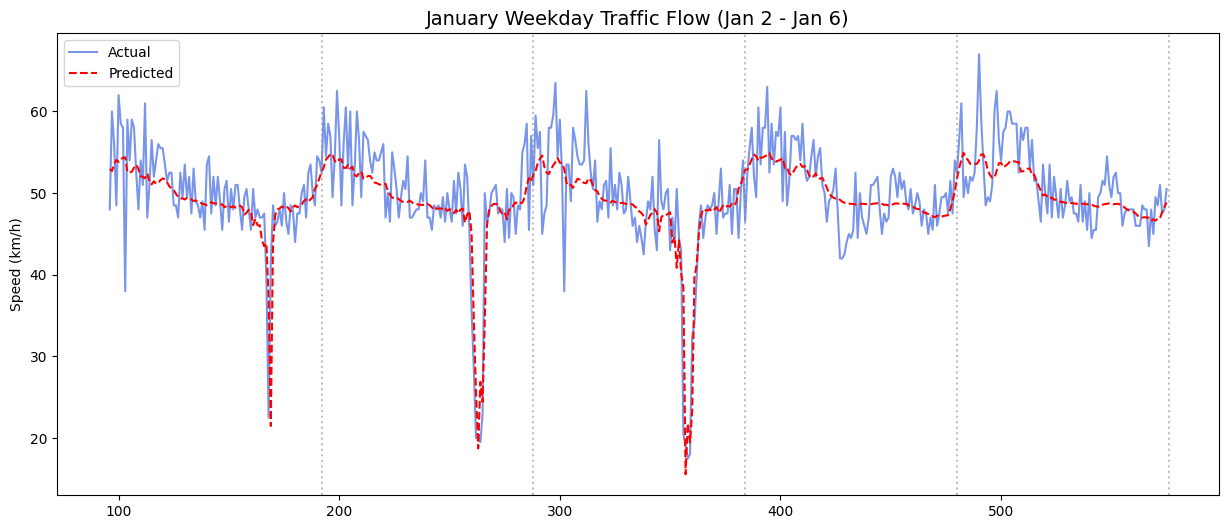

In [ ]:
# 7. 시각화 (승준 님 원본 스타일)
plot_df = pd.DataFrame({'실제값': y_test_unscaled, '예측값': y_pred_unscaled}).reset_index()
# [후자 사진처럼 나오게 하는 설정]
jan_start = 96  # 1월 1일(일) 데이터 96개를 건너뜀
jan_weekly_data = plot_df.iloc[jan_start : jan_start + (96 * 7)].copy()

# 평일 데이터 슬라이싱
jan_wd = jan_weekly_data.iloc[:96*5]

# ... (기존 jan_weekly_data 코드 밑에 추가) ...

# [추가] 도화지 만들기 (ax1 정의)
fig, ax1 = plt.subplots(figsize=(15, 6))

# 평일 데이터 슬라이싱
jan_wd = jan_weekly_data.iloc[:96*5]

# 가로축을 'index'로 설정 (데이터의 실제 위치인 96, 97... 사용)
ax1.plot(jan_wd['index'], jan_wd['실제값'], label='Actual', color='royalblue', alpha=0.7)
ax1.plot(jan_wd['index'], jan_wd['예측값'], label='Predicted', color='red', linestyle='--')

# 세로선(axvline)도 jan_start(96) 기준으로 그리기
for i in range(1, 6):
    ax1.axvline(x=jan_start + 96*i, color='gray', linestyle=':', alpha=0.5)

# [추가] 그래프 마무리 꾸미기
ax1.set_title('January Weekday Traffic Flow (Jan 2 - Jan 6)', fontsize=14)
ax1.set_ylabel('Speed (km/h)')
ax1.legend()
plt.show()

# 가로축을 'index'로 설정 (데이터의 실제 위치인 96, 97... 사용)
ax1.plot(jan_wd['index'], jan_wd['실제값'], label='Actual', color='royalblue', alpha=0.7)
ax1.plot(jan_wd['index'], jan_wd['예측값'], label='Predicted', color='red', linestyle='--')

# 세로선(axvline)도 jan_start(96) 기준으로 그리기
for i in range(1, 6):
    ax1.axvline(x=jan_start + 96*i, color='gray', linestyle=':', alpha=0.5)

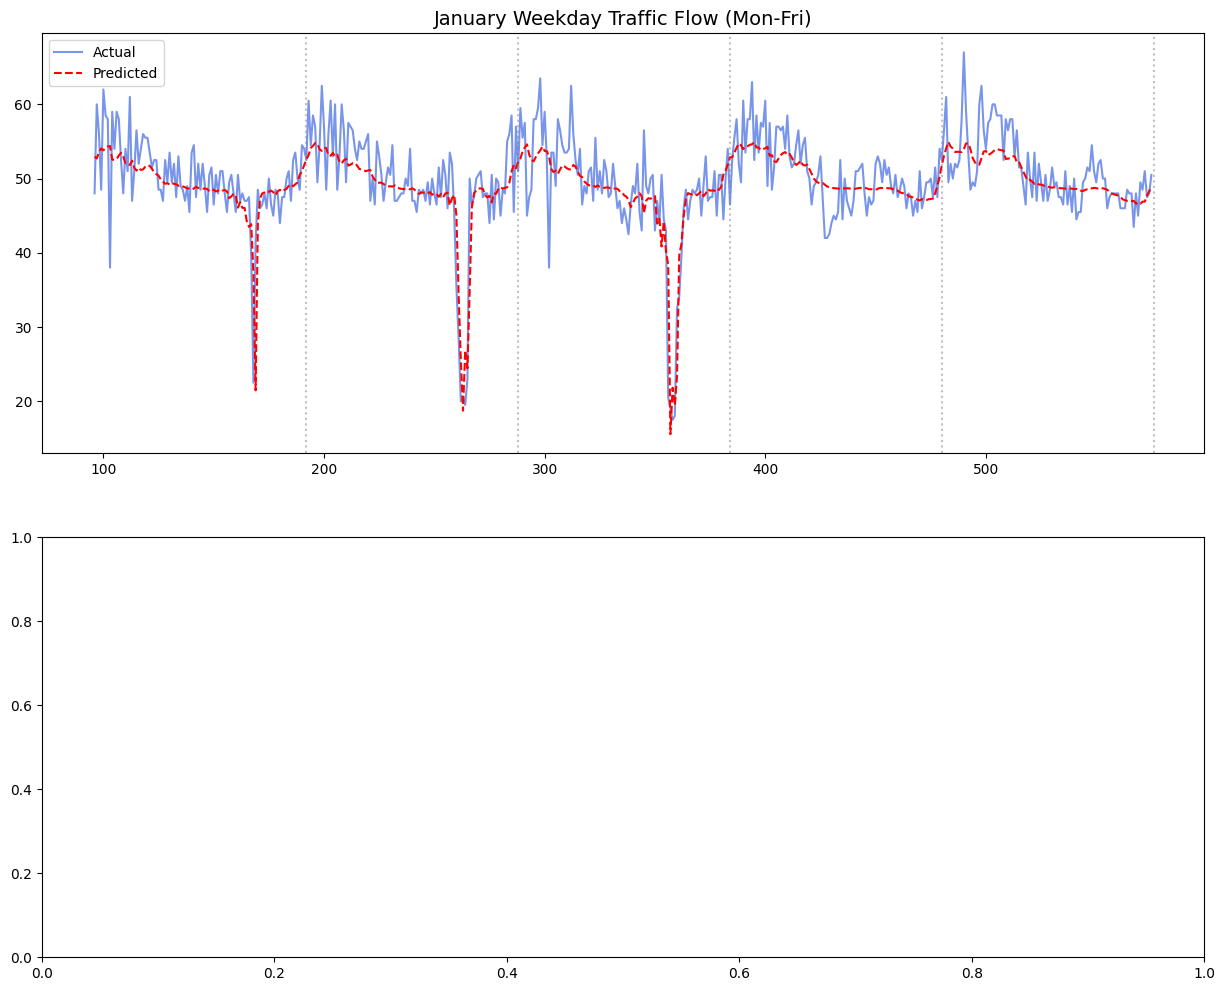

In [ ]:
# 3. 그래프 그리기 (상: 평일, 하: 주말)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 12))



# --- 1월 평일 그래프 (Mon-Fri Pattern) ---

# 가로축을 그냥 순서로 그리기 (2월 코드와 동일 방식)

jan_wd = jan_weekly_data.iloc[:96*5] # 월~금

ax1.plot(jan_wd['index'], jan_wd['실제값'], label='Actual', color='royalblue', alpha=0.7)

ax1.plot(jan_wd['index'], jan_wd['예측값'], label='Predicted', color='red', linestyle='--')

ax1.set_title('January Weekday Traffic Flow (Mon-Fri)', fontsize=14)

# 가로축에 요일 가이드 표시 (하루 단위로 세로선)

for i in range(1, 6):

    ax1.axvline(x=jan_start + 96*i, color='gray', linestyle=':', alpha=0.5)

ax1.legend()

In [ ]:
# --- 1월 주말 그래프 (Sat-Sun Pattern) ---

jan_we = jan_weekly_data.iloc[96*5:] # 토~일

if not jan_we.empty:

    ax2.plot(jan_we['index'], jan_we['실제값'], label='Actual', color='seagreen', alpha=0.7)

    ax2.plot(jan_we['index'], jan_we['예측값'], label='Predicted', color='orange', linestyle='--')

    ax2.set_title('January Weekend Traffic Flow (Sat-Sun)', fontsize=14)

    # 가로축에 요일 가이드 표시

    ax2.axvline(x=jan_start + 96*6, color='gray', linestyle=':', alpha=0.5)

    ax2.legend()

else:

    ax2.text(0.5, 0.5, "Weekend Data Range Exceeded", ha='center', fontsize=12)



plt.tight_layout()

plt.show()

<Figure size 640x480 with 0 Axes>

In [ ]:
# KPI 지표

rmse = np.sqrt(mean_squared_error(y_test_unscaled, y_pred_unscaled))

print(f"✅ 15분 단위 모델 RMSE: {rmse:.2f} km/h")

✅ 15분 단위 모델 RMSE: 4.26 km/h


In [ ]:
# 6-3. KPI 성능 지표 출력 (RMSE, MAE)

rmse = np.sqrt(mean_squared_error(y_test_unscaled, y_pred_unscaled))

mae = mean_absolute_error(y_test_unscaled, y_pred_unscaled)

print(f"✅ 모델 성능 지표 (KPI):")

print(f"- RMSE (Root Mean Squared Error): {rmse:.2f} km/h")

print(f"- MAE (Mean Absolute Error): {mae:.2f} km/h")

✅ 모델 성능 지표 (KPI):
- RMSE (Root Mean Squared Error): 4.26 km/h
- MAE (Mean Absolute Error): 3.00 km/h


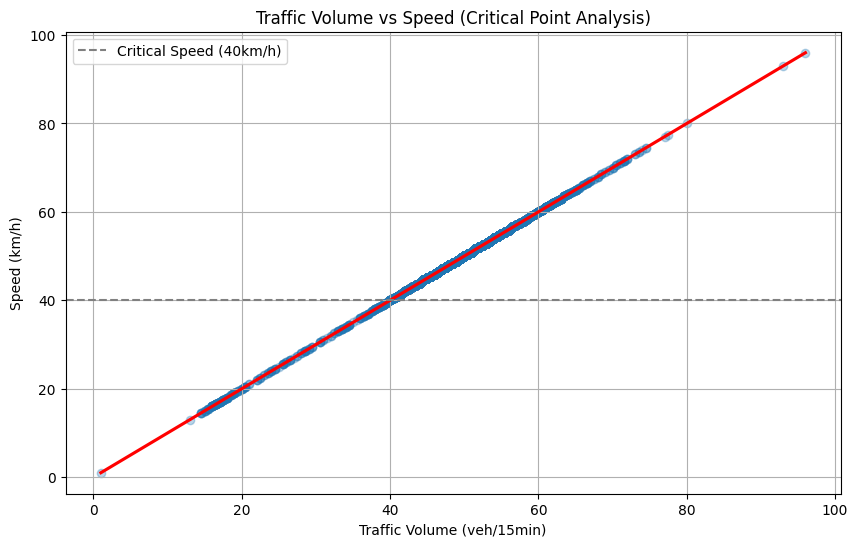

📊 분석 결과: 해당 구간의 임계 교통량은 약 27.8대/15분입니다.


In [ ]:
# --- 추가 코드: 7. 산점도 분석 (임계점 도출) ---
plt.figure(figsize=(10, 6))
# 0~1로 스케일링 된 데이터를 다시 원래 수치로 돌려서 분석
original_features = scaler.inverse_transform(df_scaled)
volume = original_features[:, 0] # 교통량
speed = original_features[:, 1]  # 속도

sns.regplot(x=volume, y=speed, scatter_kws={'alpha':0.3}, line_kws={'color':'red'})
plt.axhline(y=40, color='gray', linestyle='--', label='Critical Speed (40km/h)') # 임계 속도 예시
plt.title('Traffic Volume vs Speed (Critical Point Analysis)')
plt.xlabel('Traffic Volume (veh/15min)')
plt.ylabel('Speed (km/h)')
plt.legend()
plt.grid(True)
plt.show()

# 실제 임계 교통량 계산 (예: 속도가 40 이하로 떨어지는 시점의 평균 교통량)
critical_volume = df_final[df_final.iloc[:, 1] <= 40].iloc[:, 0].mean()
print(f"📊 분석 결과: 해당 구간의 임계 교통량은 약 {critical_volume:.1f}대/15분입니다.")

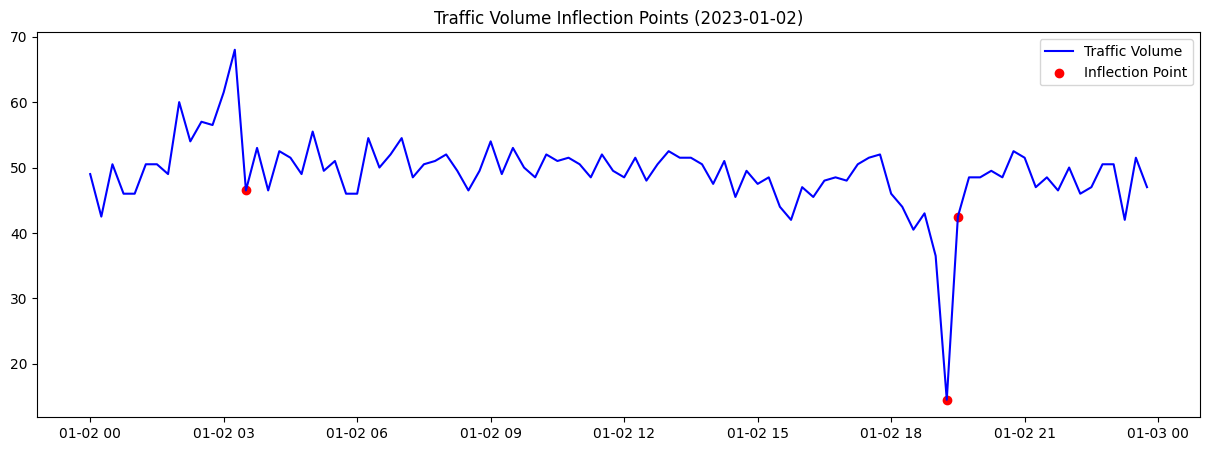

In [ ]:
# --- 추가 코드: 8. 교통량 변곡점 분석 ---
# [수정] '값' 대신 정확한 컬럼명 사용 (이미지상 에러 방지)
# 만약 교통량 컬럼명이 '값_교통량'이라면 그걸 써주세요.
vol_col = '값' # 또는 '값_교통량'

# .iloc[:, 0]을 쓰면 이름과 상관없이 첫 번째 열(교통량)을 확실히 가져옵니다.
df_final['volume_diff'] = df_final.iloc[:, 0].diff().fillna(0)

# 특정 날짜 피크 타임 시각화
# [수정] 2025년 데이터라면 2025-01-06, 2023년 데이터라면 2023-01-02 등으로 날짜를 맞추세요.
target_date = '2023-01-02' # 월요일 예시
sample_day = df[df['열1'].dt.date == pd.to_datetime(target_date).date()].index
peak_data = df_final.loc[sample_day]

plt.figure(figsize=(15, 5))
# 가로축은 '열1' (시간), 세로축은 교통량 값
plt.plot(df.loc[sample_day, '열1'], peak_data.iloc[:, 0], label='Traffic Volume', color='blue')

# 변화율이 큰 지점(변곡점) 강조
inflection_points = peak_data[peak_data['volume_diff'].abs() > peak_data['volume_diff'].std() * 2]
plt.scatter(df.loc[inflection_points.index, '열1'], inflection_points.iloc[:, 0], color='red', label='Inflection Point')

plt.title(f'Traffic Volume Inflection Points ({target_date})')
plt.legend()
plt.show()

In [ ]:
# --- 추가 코드: 9. 구간별 시차 분석 (Cross-Correlation) ---
# 예: df_final에 'sec1_vol', 'sec2_vol' 등이 있다고 가정할 때
def cross_corr_analysis(data1, data2, max_lag=8):
    lags = range(-max_lag, max_lag + 1)
    corrs = [data1.corr(data2.shift(lag)) for lag in lags]
    return lags, corrs

# 1구간과 2구간의 교통량 시차 분석 (가상의 컬럼명 사용, 승준 님 데이터에 맞춰 수정 필요)
# lags, corrs = cross_corr_analysis(df_final['구간1_교통량'], df_final['구간2_교통량'])

# plt.figure(figsize=(8, 4))
# plt.stem(lags, corrs)
# plt.title('Cross-Correlation between Section 1 & 2')
# plt.xlabel('Lag (unit: 15min)')
# plt.ylabel('Correlation')
# plt.show()